# 과제 4 — Diffusion Policy 학습 및 ACT 비교

**과제 내용**: 과제 3과 같은 데이터셋으로 Diffusion Policy를 학습하고, 실제 로봇에서 10회 평가해 과제 3의 ACT 정책과 성공률·동작의 부드러움·반응성을 비교한다. 같은 Diffusion Policy를 DDIM 스케줄러로 denoising 횟수만 10으로 줄여 10회 더 평가하고, denoising 횟수가 성공률과 실시간성에 주는 영향을 분석한다. 학습된 정책은 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1~3과 같은 저장소, assignments 폴더)에 `assignment_4.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고, 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- Diffusion Policy는 과제 3의 ACT와 **같은 학습 데이터셋**으로 학습해야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 비교 대상 ACT는 과제 3에서 성공률이 가장 높았던 chunk_size의 정책을 쓴다. 과제 3 이후 평가 환경(조명, 카메라 위치, 물체 위치 표시)이 바뀌지 않았다면 과제 3의 ACT 평가 결과를 **재사용해도 된다.** 바뀌었다면 ACT도 다시 10회 평가한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [20]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136084"
NAME = "윤성민"
HF_USER = "SEONGMIN1234"

TASK = "Grab the black cube."   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/so101-pick-cube-2cam-50ep_20261112_132007"   # 과제 3과 같은 학습 데이터셋 (0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다)

# 비교 대상 ACT 정책 (과제 3에서 성공률이 가장 높았던 chunk_size)
ACT_CHUNK_SIZE = 50
ACT_POLICY_REPO = f"{HF_USER}/act_pick_cube_chunk{ACT_CHUNK_SIZE}"

# Diffusion Policy
DP_POLICY_REPO = f"{HF_USER}/diffusion_pick-cube"

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 그대로 적을 것 (ACT 평가를 재사용하면 과제 3의 평가 데이터셋 repo를 그대로 적는다)
CONDITIONS = ["act", "dp", "dp_ddim10"]
LABELS = {"act": f"ACT (chunk{ACT_CHUNK_SIZE})", "dp": "DP (DDPM)", "dp_ddim10": "DP (DDIM 10)"}
EVAL_DATASETS = {
    "act":       f"{HF_USER}/rollout_act_pick-cube_chunk50",
    "dp":        f"{HF_USER}/rollout_diffusion_pick-cube_ddpm",
    "dp_ddim10": f"{HF_USER}/rollout_diffusion_pick-cube_ddim10",
}
WANDB_URL = "https://forge.coreweave.com/wandb/seougmin1234-study-com/so101-diffusion-hw4?nw=nwuserseougmin1234"   # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("ACT 정책      :", f"https://huggingface.co/{ACT_POLICY_REPO}")
print("DP 정책       :", f"https://huggingface.co/{DP_POLICY_REPO}")
for k in CONDITIONS:
    print(f"{LABELS[k]:<14} 평가 :", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2021136084 윤성민
태스크        : Grab the black cube.
학습 데이터셋 : https://huggingface.co/datasets/SEONGMIN1234/so101-pick-cube-2cam-50ep_20261112_132007
ACT 정책      : https://huggingface.co/SEONGMIN1234/act_pick_cube_chunk50
DP 정책       : https://huggingface.co/SEONGMIN1234/diffusion_pick-cube
ACT (chunk50)  평가 : https://huggingface.co/datasets/SEONGMIN1234/rollout_act_pick-cube_chunk50
DP (DDPM)      평가 : https://huggingface.co/datasets/SEONGMIN1234/rollout_diffusion_pick-cube_ddpm
DP (DDIM 10)   평가 : https://huggingface.co/datasets/SEONGMIN1234/rollout_diffusion_pick-cube_ddim10
wandb         : https://forge.coreweave.com/wandb/seougmin1234-study-com/so101-diffusion-hw4?nw=nwuserseougmin1234


In [21]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [22]:
# Hub 접근 확인 — 6개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (ACT_POLICY_REPO, "model"), (DP_POLICY_REPO, "model")]
checks += [(EVAL_DATASETS[k], "dataset") for k in CONDITIONS]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] SEONGMIN1234/so101-pick-cube-2cam-50ep_20261112_132007  (파일 10개)
OK   [model  ] SEONGMIN1234/act_pick_cube_chunk50  (파일 8개)
OK   [model  ] SEONGMIN1234/diffusion_pick-cube  (파일 8개)
OK   [dataset] SEONGMIN1234/rollout_act_pick-cube_chunk50  (파일 8개)
OK   [dataset] SEONGMIN1234/rollout_diffusion_pick-cube_ddpm  (파일 44개)
OK   [dataset] SEONGMIN1234/rollout_diffusion_pick-cube_ddim10  (파일 44개)


## 1. 실험 설계

### 1-1. 배경
Diffusion Policy는 행동을 한 번에 회귀하지 않는다. 가우시안 노이즈에서 출발해 노이즈를 조금씩 걷어내며(denoising) 행동 시퀀스를 만든다. 학습할 때는 행동에 섞인 노이즈를 맞히도록 배우고, 추론할 때는 이 과정을 `num_inference_steps`번 반복한다.

- `n_obs_steps`: 정책에 넣는 과거 관측 프레임 수
- `horizon`: 한 번의 추론으로 생성하는 행동 시퀀스의 길이
- `n_action_steps`: 생성한 시퀀스 중 실제로 실행하는 스텝 수. 이만큼 실행한 뒤 다시 추론한다.

ACT와 비교하면 다음과 같다.
- ACT는 행동을 L1 손실로 직접 회귀한다. 같은 상황에서 시연이 여러 갈래로 나뉘면(예: 물체를 왼쪽에서 잡기도 하고 오른쪽에서 잡기도 함) 회귀 출력은 그 평균 쪽으로 끌려가기 쉽다. ACT는 CVAE 구조로 이 문제를 일부 완화한다.
- Diffusion Policy는 행동 분포에서 샘플링하므로 여러 갈래의 시연을 그대로 표현할 수 있다. 대신 추론할 때마다 denoising을 여러 번 반복해야 하므로 느리다.
- 학습에 쓴 DDPM 스케줄러 대신 DDIM 스케줄러를 쓰면 **재학습 없이** denoising 횟수를 줄여 추론을 빠르게 할 수 있다. 다만 횟수를 너무 줄이면 행동의 품질이 떨어질 수 있다.

아래 셀은 학습한 정책의 설정을 데이터셋의 fps로 환산해 초 단위로 보여준다.

In [23]:
# 학습 데이터셋의 fps로 관측·행동 구간 길이 환산
import pandas as pd
import matplotlib.pyplot as plt

def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
dp_cfg = load_json(DP_POLICY_REPO, "config.json") or {}
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for key in ["n_obs_steps", "horizon", "n_action_steps"]:
        v = dp_cfg.get(key)
        if v:
            print(f"{key:<15} = {v:>3d} -> {v/fps:5.2f} s")
    if dp_cfg.get("n_action_steps"):
        n_plan = ep_len_s * fps / dp_cfg["n_action_steps"]
        print(f"\n평균 에피소드 한 번에 약 {n_plan:.0f}회 다시 추론한다.")

fps: 15, 에피소드 수: 50, 평균 에피소드 길이: 17.4 s

n_obs_steps     =   2 ->  0.13 s
horizon         =  64 ->  4.27 s
n_action_steps  =  32 ->  2.13 s

평균 에피소드 한 번에 약 8회 다시 추론한다.


### 1-2. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

- 성공률이 가장 높을 것으로 예상하는 조건(ACT / DP (DDPM) / DP (DDIM 10))과 이유: ACT의 Chunk size 50이 가장 높은 성공률을 보일 것으로 예상합니다. 과제 3에서 ACT Chunk 50이 다른 청크 크기보다 높은 성공률을 기록했으며, 행동을 직접 예측하는 방식이므로 반복적인 추론으로 인하 지연이 적어 실제 로봇 제어에서 유리할 것으로 판단합니다.
- 동작이 가장 부드러울 것으로 예상하는 조건과 이유: DP(DDPM)의 동작이 가장 부드러울 것으로 예상합니다. Diffusion Policy는 노이즈를 점진적으로 제거하는 과정을 통해 연속적인 행동 궤적을 생성하므로, 충분한 Denoising(노이즈 제거) 단계를 거치면 비교적 안정적이고 부드러운 궤적을 생성할 수 있을 것으로 판단하였습니다.
- denoising 횟수를 10으로 줄였을 때 성공률과 동작이 어떻게 달라질지와 이유: DDIM 10은 DDPM보다 추론 시가이 감소하여 로봇이 행동 사이에 멈칫하는 현상이 줄어들 것으로 예상합니다. 반면 노이즈 제거 횟수가 줄어들면ㄴ서 행동 궤적의 정밀도가 다소 낮아져 성공률이나 동작의 부드러움이 감소할 것 같습니다.

### 1-3. 정책 설정 확인
아래 셀은 Diffusion Policy의 주요 설정을 출력하고, ACT와 같은 학습 데이터셋을 썼는지 확인한다.

In [24]:
act_tc = load_json(ACT_POLICY_REPO, "train_config.json") or {}
dp_tc = load_json(DP_POLICY_REPO, "train_config.json") or {}

print("[Diffusion Policy 주요 설정]")
for key in ["type", "n_obs_steps", "horizon", "n_action_steps", "noise_scheduler_type",
            "num_train_timesteps", "num_inference_steps", "crop_shape", "vision_backbone"]:
    print(f"  {key:<22}: {dp_cfg.get(key)}")
if dp_cfg and dp_cfg.get("num_inference_steps") is None:
    print("  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다")

cmp_df = pd.DataFrame([
    {"policy": "ACT", "dataset": act_tc.get("dataset", {}).get("repo_id"),
     "steps": act_tc.get("steps"), "batch_size": act_tc.get("batch_size"), "seed": act_tc.get("seed")},
    {"policy": "Diffusion", "dataset": dp_tc.get("dataset", {}).get("repo_id"),
     "steps": dp_tc.get("steps"), "batch_size": dp_tc.get("batch_size"), "seed": dp_tc.get("seed")},
]).set_index("policy")
display(cmp_df)

same_dataset = cmp_df["dataset"].nunique(dropna=False) == 1 and cmp_df["dataset"].notna().all()
print(("[일치]   " if same_dataset else "[불일치] ") + "학습 데이터셋")
print(("[일치]   " if dp_cfg.get("type") == "diffusion" else "[불일치] ") + f"정책 종류: {dp_cfg.get('type')}")

[Diffusion Policy 주요 설정]
  type                  : diffusion
  n_obs_steps           : 2
  horizon               : 64
  n_action_steps        : 32
  noise_scheduler_type  : DDPM
  num_train_timesteps   : 100
  num_inference_steps   : None
  crop_shape            : None
  vision_backbone       : resnet18
  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다


,dataset,steps,batch_size,seed
policy,,,,
ACT,SEONGMIN1234/so101-pick-cube-2cam-50ep,100000,4,1000
Diffusion,SEONGMIN1234/so101-pick-cube-2cam-50ep,100000,4,1000


[일치]   학습 데이터셋
[일치]   정책 종류: diffusion


## 2. 학습

### 2-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 전체를 아래 코드 블록에 붙여 넣는다.

```bash
lerobot-train \
  --dataset.repo_id=SEONGMIN1234/so101-pick-cube-2cam-50ep \
  --dataset.root=/home/work/lerobot/datasets/so101-pick-cube-2cam-50ep \
  --dataset.video_backend=pyav \
  --policy.type=diffusion \
  --policy.device=cuda \
  --policy.repo_id=SEONGMIN1234/diffusion_pick-cube \
  --policy.push_to_hub=true \
  --policy.private=false \
  --output_dir=/home/work/lerobot/outputs/diffusion_hw4_sharded_100k \
  --job_name=diffusion_hw4_sharded_100k \
  --batch_size=4 \
  --num_workers=0 \
  --steps=100000 \
  --seed=1000 \
  --save_freq=5000 \
  --log_freq=100 \
  --wandb.enable=true \
  --wandb.disable_artifact=true \
  --wandb.project=so101-diffusion-hw4
```

> Diffusion Policy에 필요한 패키지는 `lerobot[all]`에 포함되어 있다. 학습 기본값은 `steps=100000`, `batch_size=8`이다.
>
> Diffusion Policy는 보통 ACT보다 수렴이 느려 학습 step을 더 많이 잡는다. steps와 batch_size는 과제 3과 달라도 되지만, 바꾼 이유를 2-2에 적는다. 이미지 전처리 설정(`crop_shape` 등)은 기본값이 본인 카메라 해상도에 맞는지 1-3의 출력으로 확인할 것.

### 2-2. 학습 환경
`[작성]`
- GPU: NVIDIA H200
- 학습 step 수 / batch_size: 100,000/4
- 소요 시간 (과제 3의 ACT와 비교): 5시간 42분 41초
- 기본값에서 변경한 하이퍼파라미터와 이유 (없으면 "없음"): CPU RAM이 4GiB로 제한된 학습 환경을 고려하여 Batch Size를 기본값 8에서 4로 줄이고, 데이터 로딩 작업자 수(num_workers)를 0으로 설정하여 메모리 사용량을 줄임.

### 2-3. 학습 곡선
`[작성]` loss 곡선을 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw4.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw4.png)

In [25]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 둘째 열 loss (열 이름은 본인 파일에 맞게 수정)
import os

CSV_PATH = "images/loss_hw4.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Diffusion Policy training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


In [26]:
# [작성] 학습 종료 시점의 손실 (학습 로그 마지막 줄에서 확인)
# Diffusion Policy는 노이즈 예측 오차(MSE)를 loss로 출력한다
dp_final_loss = 0.0054269
print("Diffusion Policy 최종 loss:", dp_final_loss)

Diffusion Policy 최종 loss: 0.0054269


## 3. 실로봇 평가 (조건별 10회)

### 3-1. 평가 프로토콜
1. 과제 3에서 표시한 물체 시작 위치 10곳을 그대로 쓴다. **세 조건 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준은 과제 3과 같게 두고 아래에 다시 적는다. 평가 도중 바꾸지 않는다.

`[작성]` 성공 기준
- 성공: 상자를 집어 바구니에 넣기
- 실패: 이를 하지 못하는 경우
- 에피소드 제한 시간(초): 180초
- ACT 평가 결과 재사용 여부 (재사용 / 다시 평가)와 이유: 재사용 이전 과제에서 해당 테스크 수행을 잘 하였기 때문

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).
- Diffusion Policy는 추론이 무겁다. GPU가 있는 PC에서 돌리고, 필요하면 `--device=cuda`를 명시한다.

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어를 붙여 넣는다. DP (DDIM 10)은 같은 정책에 추론 설정만 덮어써서 평가한다. ACT를 다시 평가했다면 그 명령어도 함께 붙여 넣는다.

```bash
# DP (DDPM)
python ~/so_arm_ws/camera_bridge/rollout_with_2cameras.py \
  --strategy.type=episodic \
  --strategy.reset_to_initial_position=false \
  --policy.path=SEONGMIN1234/diffusion_pick-cube \
  --policy.noise_scheduler_type=DDPM \
  --policy.num_inference_steps=100 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=follower1 \
  --robot.disable_torque_on_disconnect=true \
  --robot.max_relative_target=5 \
  --robot.cameras="{overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15}, wrist: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15}}" \
  --inference.type=sync \
  --dataset.repo_id="$DDPM_REPO" \
  --dataset.root="$HOME/so_arm_ws/rollouts/hw4_ddpm" \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=180 \
  --dataset.reset_time_s=60 \
  --dataset.fps=15 \
  --dataset.push_to_hub=false \
  --dataset.rgb_encoder.vcodec=h264 \
  --dataset.rgb_encoder.preset=ultrafast \
  --fps=15 \
  --device=cpu \
  --resume=true \
  --return_to_initial_position=false \
  --display_data=false \
  --play_sounds=false

# DP (DDIM 10)
export SO_ARM_CAMERA_HOST="$(ip route show default | awk '{print $3}')"
export SO_ARM_OVERHEAD_URL="http://${SO_ARM_CAMERA_HOST}:8765/overhead/video"
export SO_ARM_WRIST_URL="http://${SO_ARM_CAMERA_HOST}:8765/wrist/video"

python ~/so_arm_ws/camera_bridge/rollout_with_2cameras.py \
  --strategy.type=episodic \
  --strategy.reset_to_initial_position=false \
  --policy.path=SEONGMIN1234/diffusion_pick-cube \
  --policy.noise_scheduler_type=DDIM \
  --policy.num_inference_steps=10 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=follower1 \
  --robot.disable_torque_on_disconnect=true \
  --robot.max_relative_target=5 \
  --robot.cameras="{overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15}, wrist: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15}}" \
  --inference.type=sync \
  --dataset.repo_id=SEONGMIN1234/rollout_diffusion_pick-cube_ddim10 \
  --dataset.root="$HOME/so_arm_ws/rollouts/hw4_ddim10" \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=180 \
  --dataset.reset_time_s=60 \
  --dataset.fps=15 \
  --dataset.push_to_hub=false \
  --dataset.rgb_encoder.vcodec=h264 \
  --dataset.rgb_encoder.preset=ultrafast \
  --fps=15 \
  --device=cpu \
  --return_to_initial_position=false \
  --display_data=false \
  --play_sounds=false

In [27]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CONDITIONS:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"{LABELS[k]:<14} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f" {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

ACT (chunk50)  에피소드 10개, 프레임 6302, fps 15  -> 통과
DP (DDPM)      에피소드 10개, 프레임 1187, fps 15  -> 통과
DP (DDIM 10)   에피소드 10개, 프레임 8487, fps 15  -> 통과
 act 이름 규칙: 통과
 dp 이름 규칙: 통과
 dp_ddim10 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다. ACT 평가를 재사용했다면 과제 3의 결과를 그대로 옮긴다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. 추론 때문에 동작이 멈칫하는 구간이 보이면 함께 적는다. (예: "큐브 위치를 놓침", "다시 추론할 때마다 팔이 잠깐 멈춤", "파지 직전 좌우로 머뭇거림")

In [28]:
import pandas as pd

results = {
    "act": [
        {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 1, "position": 2, "success": False, "smooth": None, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 2, "position": 3, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 3, "position": 4, "success": False, "smooth": 2, "note": "바구니에 큐브를 집지 않은 상태로 넣음"},
        {"episode": 4, "position": 5, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 5, "position": 6, "success": True, "smooth": 4, "note": ""},
        {"episode": 6, "position": 7, "success": False, "smooth": 2, "note": "그리퍼가 제대로 큐브를 잡지 못함"},
        {"episode": 7, "position": 8, "success": True, "smooth": 4, "note": ""},
        {"episode": 8, "position": 9, "success": True, "smooth": 4, "note": ""},
        {"episode": 9, "position": 10, "success": True, "smooth": 5, "note": ""},
    ],

    "dp": [
        {
            "episode": i,
            "position": i + 1,
            "success": False,
            "smooth": 0,
            "note": "추론 속도가 느려서 많이 떨림"
        }
        for i in range(10)
    ],

    "dp_ddim10": [
        {
            "episode": i,
            "position": i + 1,
            "success": False,
            "smooth": 0,
            "note": "추론 속도가 느려서 많이 떨림"
        }
        for i in range(10)
    ],
}

LABELS = {
    "act": "ACT Chunk 50",
    "dp": "DDPM 100",
    "dp_ddim10": "DDIM 10"
}

res_df = pd.concat(
    [
        pd.DataFrame(v).assign(condition=k)
        for k, v in results.items()
    ],
    ignore_index=True
)

summary = (
    res_df.assign(success=res_df["success"].astype(float))
    .groupby("condition", sort=False)
    .agg(
        success_rate=("success", "mean"),
        mean_smooth=("smooth", "mean")
    )
)

summary["success_rate"] = (
    summary["success_rate"] * 100
).round(0)

summary["mean_smooth"] = summary["mean_smooth"].round(2)
summary.index = [LABELS[k] for k in summary.index]

display(summary)

,success_rate,mean_smooth
ACT Chunk 50,40.0,3.0
DDPM 100,0.0,0.0
DDIM 10,0.0,0.0


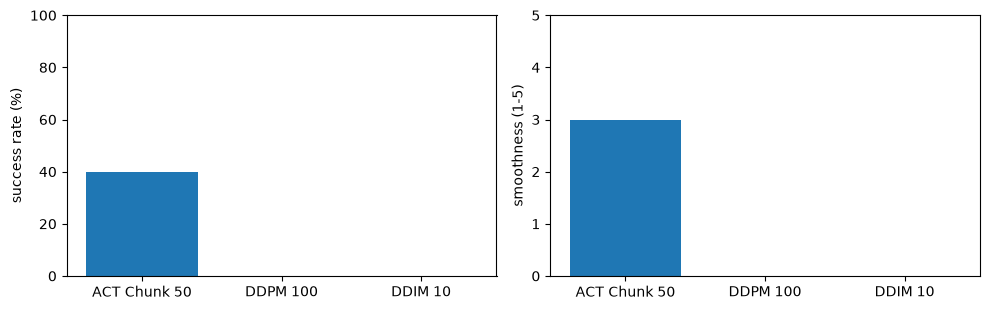

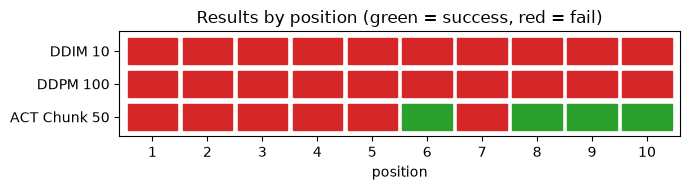

In [29]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
labels = list(summary.index)
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = 조건, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CONDITIONS):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CONDITIONS) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CONDITIONS)))
ax.set_yticklabels([LABELS[k] for k in CONDITIONS]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
과제 3의 3-4와 같은 방법으로, DP (DDPM)과 DP (DDIM 10)을 각각 3회씩 추가로 시도한다. 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮기고**, 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음) ACT는 과제 3의 반응성 테스트 결과와 비교한다.

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다. DDIM 10은 `--policy.noise_scheduler_type=DDIM --policy.num_inference_steps=10`을 함께 준다.

`[작성]` 아래 `reactivity`를 채운다.

In [30]:
reactivity = {
    "dp": [
        {
            "trial": i,
            "followed": False,
            "note": "추론 속도가 느려서 해당 시간 내에 태스크를 수행하지 못함"
        }
        for i in range(3)
    ],

    "dp_ddim10": [
        {
            "trial": i,
            "followed": False,
            "note": "많이 떨려서 상자를 제대로 잡지 못함"
        }
        for i in range(3)
    ],
}

react_df = pd.concat(
    [
        pd.DataFrame(v).assign(condition=LABELS[k])
        for k, v in reactivity.items()
    ],
    ignore_index=True
)

print(
    react_df.groupby("condition", sort=False)["followed"]
    .apply(lambda s: f"{int(s.fillna(False).sum())}/3")
)

display(react_df)

condition
DDPM 100    0/3
DDIM 10     0/3
Name: followed, dtype: object


,trial,followed,note,condition
0,0,False,추론 속도가 느려서 해당 시간 내에 태스크를 수행하지 못함,DDPM 100
1,1,False,추론 속도가 느려서 해당 시간 내에 태스크를 수행하지 못함,DDPM 100
2,2,False,추론 속도가 느려서 해당 시간 내에 태스크를 수행하지 못함,DDPM 100
3,0,False,많이 떨려서 상자를 제대로 잡지 못함,DDIM 10
4,1,False,많이 떨려서 상자를 제대로 잡지 못함,DDIM 10
5,2,False,많이 떨려서 상자를 제대로 잡지 못함,DDIM 10


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
ACT와 Diffusion Policy의 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: ACT의 청크 경계 튐, DP의 추론 중 멈칫함, DDIM 10의 궤적 흔들림)

![act](images/hw4_act.gif)
![dp](images/hw4_dp.gif)
![dp_ddim10](images/hw4_dp_ddim10.gif)

## 4. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.
실험 결과 ACT Chunk 50이 성공률 40%로 가장 높은 성능을 보였으며, DDPM 100과 DDIM 10은 모두 성공률 0%를 기록하였다. Diffusion Policy(확산 정책)는 CPU 환경에서 추론 속도가 느려 제한 시간 내에 작업을 완료하지 못했다. 따라서 이번 실험에서는 정책의 학습 성능뿐만 아니라 실제 로봇에서의 추론 속도가 성공률에 큰 영향을 미친다는 것을 확인하였다.


**4-2. 행동 생성 방식의 차이** — ACT와 Diffusion Policy의 동작에서 관찰된 차이(궤적의 부드러움, 머뭇거림, 파지 위치 선택 등)를 두 정책의 행동 생성 방식(회귀와 샘플링)으로 설명하라.
ACT는 회귀 기반으로 행동을 직접 예측하기 때문에 비교적 빠르고 안정적인 움직임을 보였다. 반면 Diffusion Policy는 반복적인 샘플링을 통해 행동을 생성하므로 추론 과정에서 지연이 발생하였다. 실제 실험에서도 ACT의 평균 부드러움 점수는 3점이었지만, DDPM과 DDIM 10은 심한 떨림과 동작 지연으로 모두 0점을 기록하였다.



**4-3. denoising 횟수와 실시간성** — DDIM 10에서 성공률, 부드러움, 추론 때문에 멈칫하는 정도가 DDPM과 비교해 어떻게 달라졌는가? 실시간 제어 관점에서 적절한 denoising 횟수는 얼마라고 보는가?
DDPM 100과 DDIM 10은 모두 성공률 0%, 평균 부드러움 0점을 기록하였다. DDPM은 추론 속도가 느려 제한 시간 내에 작업을 수행하지 못했고, DDIM 10은 동작 중 심한 떨림으로 큐브를 제대로 잡지 못했다. 따라서 노이즈 제거 횟수를 10회로 줄이는 것만으로는 안정적인 실시간 제어가 어려웠으며, 적절한 횟수를 결정하기 위해서는 GPU 환경에서 추가 실험이 필요하다.

**4-4. 반응성** — Diffusion Policy는 `n_action_steps`마다 다시 추론한다. 반응성 테스트 결과를 과제 3의 ACT 결과와 비교하고, 차이를 다시 추론하는 주기로 설명하라.
반응성 테스트에서 DDPM 100과 DDIM 10은 각각 3회 모두 실패하여 성공률 0%를 기록하였다. Diffusion Policy는 32개 행동을 실행한 후 다시 추론하는 구조이므로, 새로운 물체 위치를 반영하기까지 지연이 발생할 수 있다. 특히 CPU 추론 시간이 길어 물체가 이동한 상황에 빠르게 대응하지 못했으며, ACT에 비해 실시간 반응성이 부족한 모습을 보였다.

**4-5. 내 태스크에 맞는 정책** — 학습 시간, 추론 속도, 성공률을 함께 고려할 때 본인 태스크에는 ACT와 Diffusion Policy 중 무엇이 적합한가? 그 정책을 더 개선하려면 무엇을 바꿔 보겠는가?
이번 Pick-and-Place(물체 집기 및 배치) 태스크에서는 ACT가 더 적합하다고 판단하였다. Diffusion Policy는 100,000단계까지 학습했지만 CPU 추론 지연으로 성공률이 0%였던 반면, ACT는 40%의 성공률을 보였다. 향후 ACT의 성공률을 높이기 위해 학습 데이터를 추가하고, 그리퍼의 파지 위치와 동작 정확도를 개선하는 실험을 진행하고자 한다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [31]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in EVAL_DATASETS.values()),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "Diffusion Policy 업로드됨 (config.json, model.safetensors)": (
        file_ok(DP_POLICY_REPO, "config.json", "model") and file_ok(DP_POLICY_REPO, "model.safetensors", "model")),
    "ACT와 같은 학습 데이터셋 사용 (1-3)": bool(same_dataset),
}
for k in CONDITIONS:
    check_items[f"{LABELS[k]} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"{LABELS[k]} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"{LABELS[k]} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["반응성 테스트 6회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] 학습 데이터셋 접근 가능 (public)
[통과] Diffusion Policy 업로드됨 (config.json, model.safetensors)
[통과] ACT와 같은 학습 데이터셋 사용 (1-3)
[통과] ACT Chunk 50 평가 데이터셋 에피소드 10개
[통과] ACT Chunk 50 회차별 결과 10개 입력
[통과] ACT Chunk 50 실패 회차에 원인 기재
[통과] DDPM 100 평가 데이터셋 에피소드 10개
[통과] DDPM 100 회차별 결과 10개 입력
[통과] DDPM 100 실패 회차에 원인 기재
[통과] DDIM 10 평가 데이터셋 에피소드 10개
[통과] DDIM 10 회차별 결과 10개 입력
[통과] DDIM 10 실패 회차에 원인 기재
[통과] 반응성 테스트 6회 입력

모두 통과
